# Simulación multiactivo: independencia vs correlación

En clase se hicieron dos ejercicios:

- **A)** NVDA, Bimbo, Cemex y AstraZeneca simulados como **independientes**, con $V_0 = 100{,}000$ MXN y tres esquemas de inversión.
- **B)** AAPL, MSFT y NVDA simulados con **correlación**, usando la descomposición de Cholesky.

En esta tarea se revisa qué tan válido es suponer independencia entre activos de sectores distintos, y cuánto cambian los resultados cuando se incluye la correlación.

**Contenido:**
1. **Parte 1.** Ejercicio A repetido con correlación entre los factores, comparado contra el caso independiente.
2. **Parte 2.** Ejercicio B con $V_0 = 100{,}000$ MXN, simulado con activos independientes y correlacionados.
3. Conclusiones.

### Cómo se hace una comparación justa

En los dos casos se usan **exactamente los mismos números aleatorios** $\varepsilon \sim N(0, I)$. Lo único que cambia es la matriz $L$ con la que se transforman:

$$Z = L\,\varepsilon$$

| Caso | Matriz $\Sigma$ | Matriz $L$ |
|---|---|---|
| Independiente | Solo varianzas en la diagonal (covarianzas = 0) | $L = \text{diag}(\sigma_1, \dots, \sigma_k)$ |
| Correlacionado | Matriz de covarianzas completa | $L$ = Cholesky de $\Sigma$ |

Así, cada activo tiene la misma volatilidad en los dos casos, y cualquier diferencia en los resultados se debe solo a la correlación.

**Supuestos:**
- El tipo de cambio USD/MXN se trata como un factor más, así que también entra en la matriz de correlación.
- Solo se compran acciones enteras; lo que sobra queda como efectivo.

---

### Librerías

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

---

## Funciones de apoyo

Las dos partes hacen las mismas tablas y gráficas, así que se definen una sola vez.

### Mapa de calor de una matriz de correlación

In [2]:
def graficar_correlacion(corr, titulo):
    etiquetas = list(corr.columns)
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(etiquetas)))
    ax.set_xticklabels(etiquetas, rotation=45, ha="right")
    ax.set_yticks(range(len(etiquetas)))
    ax.set_yticklabels(etiquetas)
    for i in range(len(etiquetas)):
        for j in range(len(etiquetas)):
            ax.text(j, i, f"{corr.values[i, j]:.3f}", ha="center", va="center", fontsize=11)
    plt.colorbar(im, ax=ax, label="Correlación")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

### Tabla comparativa independiente vs correlacionado

Para cada portafolio y cada caso calcula el valor final esperado, el rendimiento esperado, la volatilidad del rendimiento, la probabilidad de pérdida y los percentiles 5% y 95% del valor final.

In [3]:
def resumen_casos(VT_ind, VT_corr, V0):
    filas = []
    for portafolio in VT_ind.columns:
        for caso, VT in [("Independiente", VT_ind), ("Correlacionado", VT_corr)]:
            rend = VT[portafolio] / V0 - 1
            filas.append({
                "Portafolio": portafolio,
                "Caso": caso,
                "E[V_T]": VT[portafolio].mean(),
                "Rend. esperado (%)": rend.mean() * 100,
                "Volatilidad (%)": rend.std() * 100,
                "P(pérdida) (%)": (VT[portafolio] < V0).mean() * 100,
                "Percentil 5%": VT[portafolio].quantile(0.05),
                "Percentil 95%": VT[portafolio].quantile(0.95),
            })
    return pd.DataFrame(filas).set_index(["Portafolio", "Caso"])

### Histogramas del valor final, independiente vs correlacionado

Un panel por portafolio, con los dos casos encimados en los mismos intervalos para que se puedan comparar directamente.

In [4]:
def comparar_histogramas(VT_ind, VT_corr, V0, portafolios):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, p in zip(axes, VT_ind.columns):
        bins = np.linspace(min(VT_ind[p].min(), VT_corr[p].min()),
                           max(VT_ind[p].max(), VT_corr[p].max()), 80)
        vol_ind  = (VT_ind[p] / V0 - 1).std() * 100
        vol_corr = (VT_corr[p] / V0 - 1).std() * 100

        ax.hist(VT_ind[p], bins=bins, alpha=0.5, color="gray", edgecolor="black",
                label=f"Independiente (vol. {vol_ind:.1f}%)")
        ax.hist(VT_corr[p], bins=bins, alpha=0.5, color="crimson", edgecolor="black",
                label=f"Correlacionado (vol. {vol_corr:.1f}%)")
        ax.axvline(V0, color="black", ls="--", lw=2, label="V0")

        ax.set_title(f"{p}: {portafolios[p]}")
        ax.set_xlabel("Valor final (MXN)")
        ax.legend(fontsize=9); ax.grid(alpha=0.3)

    axes[0].set_ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

### Gráfica de barras de la volatilidad de cada caso

In [5]:
def comparar_volatilidad(tabla, titulo):
    vol = tabla["Volatilidad (%)"].unstack()[["Independiente", "Correlacionado"]]
    ax = vol.plot(kind="bar", figsize=(9, 5), color=["gray", "crimson"],
                  edgecolor="black", rot=0)
    for barras in ax.containers:
        ax.bar_label(barras, fmt="%.1f%%", fontsize=10)
    ax.set_ylabel("Volatilidad del rendimiento (%)")
    ax.set_title(titulo)
    ax.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

---

# Parte 1. Ejercicio A con correlación

**Activos:** NVDA (USD), Bimbo (MXN), Cemex (MXN) y AstraZeneca (USD), más el tipo de cambio.

**Portafolios:**

| Portafolio | Pesos $w$ (NVDA, Bimbo, Cemex, AZN) |
|---|---|
| P1 | [1, 0, 0, 0] |
| P2 | [0.25, 0.25, 0.25, 0.25] |
| P3 | [0.1, 0.2, 0.3, 0.4] |

Se usa la misma simulación de clase, un solo paso a $T = 1$:

$$S_T = S_0 \exp\left[\left(\mu - \tfrac{\sigma^2}{2}\right)T + \sqrt{T}\,Z\right]$$

En el caso independiente $Z_i = \sigma_i\,\varepsilon_i$, que es justo lo que se hizo en clase. En el caso correlacionado $Z = L\,\varepsilon$, con $L$ la matriz de Cholesky.

### Activos y tipo de cambio

In [6]:
activos = {
    "NVDA":        "USD",
    "BIMBOA.MX":   "MXN",
    "CEMEXCPO.MX": "MXN",
    "AZN":         "USD",
}

tickers = list(activos.keys())
fx      = "MXN=X"            # pesos por dólar
todos   = tickers + [fx]

### Descarga de precios de los últimos 3 años

In [7]:
data = yf.download(todos, start="2023-11-01", end="2026-11-01",
                   auto_adjust=True, progress=False)

precios = data["Close"][todos].dropna()
print(f"Observaciones: {len(precios)}")
precios.tail()

Observaciones: 727


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-10-26,216.000000,63.490002,18.990000,172.059998,18.71900
2026-10-27,217.940002,64.849998,19.730000,170.080002,18.55020
2026-10-28,215.380005,61.830002,19.700001,169.509995,18.68704
2026-10-29,213.660004,63.689999,20.480000,174.399994,18.63179
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210


### Parámetros anualizados (los mismos de clase)

In [8]:
log_ret = np.log(precios / precios.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(252)
mu    = log_ret.mean() * 252 + 0.5 * sigma**2
S0    = precios.iloc[-1]

V0 = 100_000
T  = 1
M  = 10_000

pd.DataFrame({"S0": S0, "mu": mu, "sigma": sigma}).round(4)

,S0,mu,sigma
Ticker,,,
NVDA,204.6400,0.6603,0.4738
BIMBOA.MX,66.1800,0.0144,0.2995
CEMEXCPO.MX,20.2300,0.2747,0.3317
AZN,186.6500,0.1822,0.2518
MXN=X,18.8521,0.0214,0.1114


### Correlación histórica entre los factores

Antes de simular, se revisa si el supuesto de independencia ($\rho = 0$) tiene sentido para estos activos.

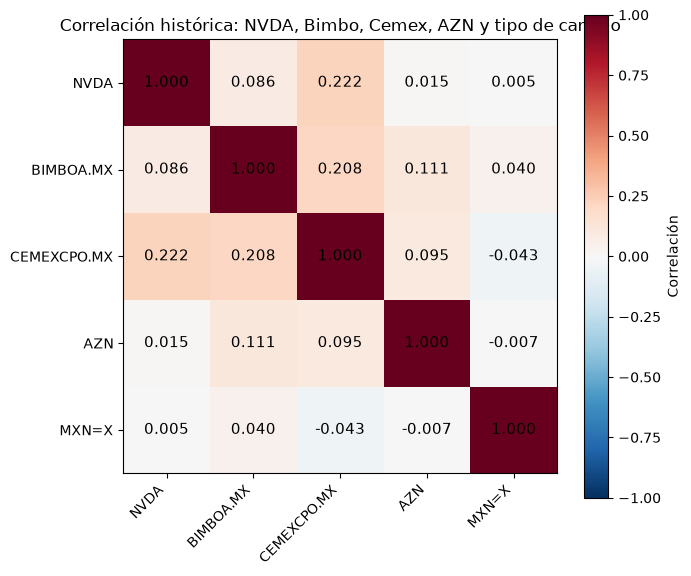

In [9]:
correlacion = log_ret.corr()
graficar_correlacion(correlacion, "Correlación histórica: NVDA, Bimbo, Cemex, AZN y tipo de cambio")

### ¿Qué observamos?

Las correlaciones son **bajas, pero no son cero**:

- **Cemex** es el activo más conectado con los demás: tiene una correlación cercana a 0.22 con NVDA y de 0.21 con Bimbo. Cemex y Bimbo cotizan en la misma bolsa y responden a la economía mexicana, y Cemex tiene una parte importante de su negocio en Estados Unidos, lo que lo acerca al mercado estadounidense.
- **AstraZeneca** casi no se mueve con NVDA ($\rho \approx 0.02$). Farmacéutica y tecnología son sectores que responden a cosas distintas.
- **El tipo de cambio** prácticamente no tiene correlación con ningún activo ($|\rho| < 0.05$).

Todas las correlaciones relevantes son **positivas**. Ninguna ayuda a compensar las caídas de otra, así que se espera que la correlación **aumente** el riesgo de los portafolios diversificados.

### Matrices $L$ de los dos casos

En el caso independiente, $L$ es una matriz diagonal con las volatilidades. En el correlacionado, $L$ sale de Cholesky sobre la covarianza anualizada.

In [10]:
Sigma = log_ret.cov() * 252

L_ind  = np.diag(sigma.values)              # Σ sin covarianzas: solo volatilidades
L_corr = np.linalg.cholesky(Sigma.values)   # Σ completa

print(f"¿L · Lᵀ reconstruye Σ? {np.allclose(L_corr @ L_corr.T, Sigma.values)}")
print("\nMatriz L con correlación:")
print(pd.DataFrame(L_corr, index=todos, columns=todos).round(4))

¿L · Lᵀ reconstruye Σ? True

Matriz L con correlación:
               NVDA  BIMBOA.MX  CEMEXCPO.MX     AZN   MXN=X
NVDA         0.4738     0.0000       0.0000  0.0000  0.0000
BIMBOA.MX    0.0256     0.2984       0.0000  0.0000  0.0000
CEMEXCPO.MX  0.0738     0.0628       0.3173  0.0000  0.0000
AZN          0.0038     0.0276       0.0188  0.2495  0.0000
MXN=X        0.0005     0.0044      -0.0060 -0.0009  0.1112


### Choques independientes y correlacionados con los mismos $\varepsilon$

Los $\varepsilon$ se generan en el mismo orden que en clase (primero los 10,000 de NVDA, luego los de Bimbo, etc.), así que **el caso independiente reproduce exactamente los resultados de clase**.

In [11]:
np.random.seed(42)
epsilon = np.random.normal(0, 1, [len(todos), M]).T

Z_ind  = epsilon @ L_ind.T
Z_corr = epsilon @ L_corr.T

print("Correlación simulada, caso independiente:")
print(pd.DataFrame(Z_ind, columns=todos).corr().round(3))
print("\nCorrelación simulada, caso correlacionado:")
print(pd.DataFrame(Z_corr, columns=todos).corr().round(3))

Correlación simulada, caso independiente:
              NVDA  BIMBOA.MX  CEMEXCPO.MX    AZN  MXN=X
NVDA         1.000     -0.009        0.027 -0.010 -0.011
BIMBOA.MX   -0.009      1.000        0.027  0.013 -0.003
CEMEXCPO.MX  0.027      0.027        1.000  0.003  0.007
AZN         -0.010      0.013        0.003  1.000  0.008
MXN=X       -0.011     -0.003        0.007  0.008  1.000

Correlación simulada, caso correlacionado:
              NVDA  BIMBOA.MX  CEMEXCPO.MX    AZN  MXN=X
NVDA         1.000      0.077        0.246  0.006 -0.008
BIMBOA.MX    0.077      1.000        0.233  0.124  0.034
CEMEXCPO.MX  0.246      0.233        1.000  0.100 -0.038
AZN          0.006      0.124        0.100  1.000  0.001
MXN=X       -0.008      0.034       -0.038  0.001  1.000


### ¿Qué observamos?

- En el caso independiente las correlaciones simuladas son prácticamente cero: solo hay ruido de muestreo.
- En el caso correlacionado se recuperan las correlaciones históricas. Por ejemplo, NVDA con Cemex y Bimbo con Cemex quedan cerca de 0.22.
- Como $L$ es triangular inferior, su primera fila solo tiene $\sigma_{NVDA}$. Por eso **NVDA es idéntico en los dos casos**, y los demás activos se "mezclan" con los choques de los que van antes.

### Precios a un año en cada caso

In [12]:
drift = (mu.values - 0.5 * sigma.values**2) * T

ST_ind  = pd.DataFrame(S0.values * np.exp(drift + np.sqrt(T) * Z_ind),  columns=todos)
ST_corr = pd.DataFrame(S0.values * np.exp(drift + np.sqrt(T) * Z_corr), columns=todos)

pd.DataFrame({"S0": S0,
              "Media S_T independiente": ST_ind.mean(),
              "Media S_T correlacionado": ST_corr.mean(),
              "Desv. S_T independiente": ST_ind.std(),
              "Desv. S_T correlacionado": ST_corr.std()}).round(2)

,S0,Media S_T independiente,Media S_T correlacionado,Desv. S_T independiente,Desv. S_T correlacionado
NVDA,204.64,395.97,395.97,199.82,199.82
BIMBOA.MX,66.18,67.42,67.41,20.69,20.67
CEMEXCPO.MX,20.23,26.49,26.55,8.94,9.07
AZN,186.65,223.58,223.64,57.42,57.56
MXN=X,18.85,19.27,19.28,2.15,2.15


### ¿Qué observamos?

La media y la desviación de **cada activo por separado** son prácticamente iguales en los dos casos. Es lo esperado: la correlación no cambia el comportamiento individual de cada acción, solo **cómo se mueven entre ellas**. Por eso cualquier diferencia en los portafolios se debe a la forma en que se combinan los activos.

### Precios en pesos

Los activos en dólares se multiplican por el tipo de cambio: el de hoy para el precio inicial y el simulado de cada escenario para el precio final, ya sea independiente o correlacionado.

In [13]:
es_usd = np.array([activos[tk] == "USD" for tk in tickers])
X0 = S0[fx]

S0_mxn = S0[tickers].values * np.where(es_usd, X0, 1)

ST_mxn_ind  = ST_ind[tickers].values  * np.where(es_usd, ST_ind[fx].values[:, None], 1)
ST_mxn_corr = ST_corr[tickers].values * np.where(es_usd, ST_corr[fx].values[:, None], 1)

pd.Series(S0_mxn, index=tickers, name="S0 en MXN").round(2)

NVDA           3857.89
BIMBOA.MX        66.18
CEMEXCPO.MX      20.23
AZN            3518.74
Name: S0 en MXN, dtype: float64

### Acciones enteras de cada portafolio

$$N_i = \left\lfloor \frac{w_i \, V_0}{S^{MXN}_{0,i}} \right\rfloor \qquad \text{Efectivo} = V_0 - \sum_i N_i\, S^{MXN}_{0,i}$$

Son las mismas acciones de clase, y se usan en los dos casos.

In [14]:
portafolios = {
    "P1": np.array([1, 0, 0, 0]),
    "P2": np.array([0.25, 0.25, 0.25, 0.25]),
    "P3": np.array([0.1, 0.2, 0.3, 0.4]),
}

acciones = {}
efectivo = {}
for nombre, w in portafolios.items():
    N = np.floor(w * V0 / S0_mxn)
    acciones[nombre] = N
    efectivo[nombre] = V0 - np.sum(N * S0_mxn)

tabla_acc = pd.DataFrame(acciones, index=tickers).T.astype(int)
tabla_acc["Efectivo"] = pd.Series(efectivo).round(2)
tabla_acc

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,Efectivo
P1,25,0,0,0,3552.65
P2,6,377,1235,7,2287.52
P3,2,302,1482,11,3610.80


### Valor final y tabla comparativa

$$V_T = \sum_i N_i \, S^{MXN}_{T,i} + \text{Efectivo}$$

In [15]:
VT_ind  = pd.DataFrame({p: ST_mxn_ind  @ N + efectivo[p] for p, N in acciones.items()})
VT_corr = pd.DataFrame({p: ST_mxn_corr @ N + efectivo[p] for p, N in acciones.items()})

tabla_p1 = resumen_casos(VT_ind, VT_corr, V0)
tabla_p1.round(2)

E[V_T]  Rend. esperado (%)  Volatilidad (%)  \
Portafolio Caso                                                             
P1         Independiente   194260.23               94.26            98.86   
           Correlacionado  194319.51               94.32            98.99   
P2         Independiente   136361.30               36.36            29.35   
           Correlacionado  136445.95               36.45            32.66   
P3         Independiente   125899.08               25.90            21.96   
           Correlacionado  125991.70               25.99            24.79   

                           P(pérdida) (%)  Percentil 5%  Percentil 95%  
Portafolio Caso                                                         
P1         Independiente            12.35      80210.08      383199.43  
           Correlacionado           12.28      80275.34      382875.65  
P2         Independiente             7.37      96054.12      189500.60  
           Correlacionado           10.33      91895.74      196720.17  
P3         Independiente            10.82      93402.69      164645.35  
           Correlacionado           13.69      89554.22      169987.33

### ¿Qué observamos?

- **El valor esperado casi no cambia.** $E[V_T]$ es una suma de valores esperados individuales, y la correlación no afecta el valor esperado de cada activo. Las diferencias entre los dos casos son de unos cuantos pesos.
- **P1 queda igual en los dos casos.** Con un solo activo no hay nada que combinar: la única diferencia es la correlación de NVDA con el tipo de cambio, que es casi cero.
- **P2 y P3 se vuelven más riesgosos.** La volatilidad de P2 sube de 29.4% a cerca de 32.7%, y la de P3 de 22.0% a cerca de 24.8%. La probabilidad de pérdida sube en ambos (P2 pasa de 7.4% a alrededor de 10.3%) y el percentil 5% empeora unos 4,000 pesos.
- **El supuesto de independencia subestima el riesgo** de los portafolios diversificados en alrededor de 11 a 13% relativo, aunque las correlaciones sean bajas.

### Distribución del valor final: independiente vs correlacionado

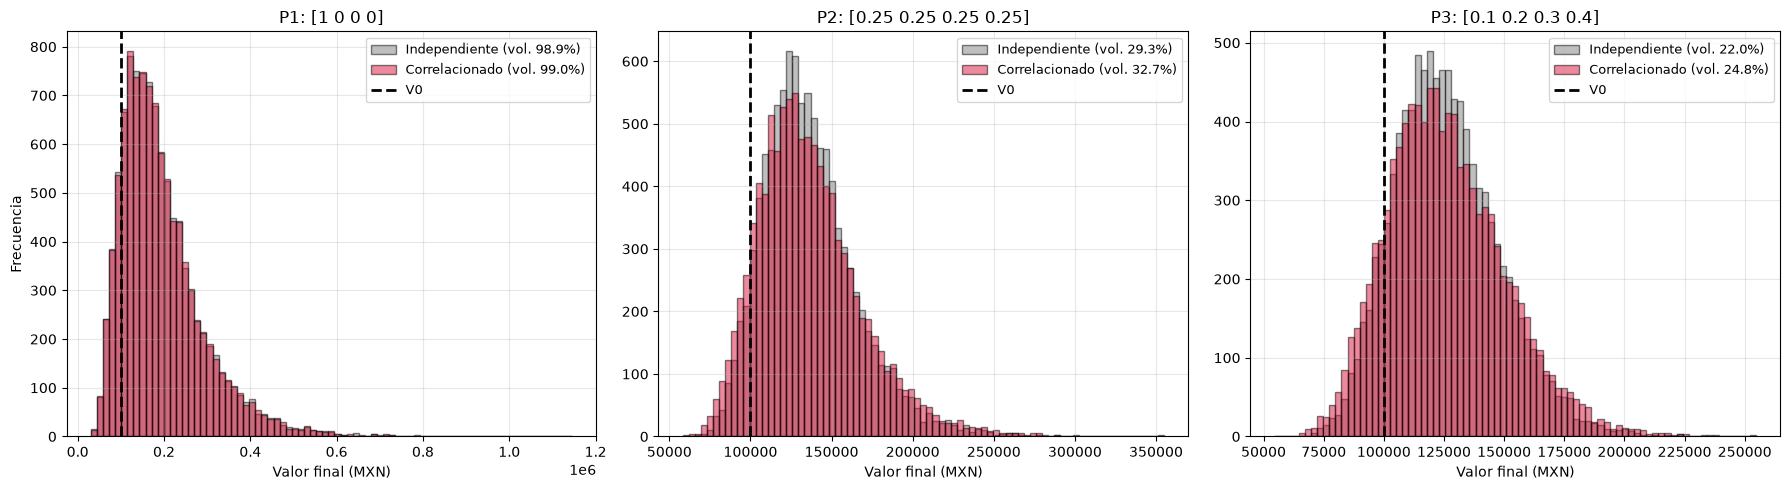

In [16]:
comparar_histogramas(VT_ind, VT_corr, V0, portafolios)

### ¿Qué observamos?

- En **P1** los dos histogramas se enciman casi por completo: es la misma distribución.
- En **P2 y P3** la distribución correlacionada (roja) es **más ancha**: tiene más escenarios en ambas colas y menos concentrados en el centro. Como los activos tienden a subir y bajar juntos, los escenarios extremos son más frecuentes: cuando a uno le va mal, es más probable que a los otros también.
- El centro de las distribuciones casi no se mueve, porque el valor esperado es el mismo.

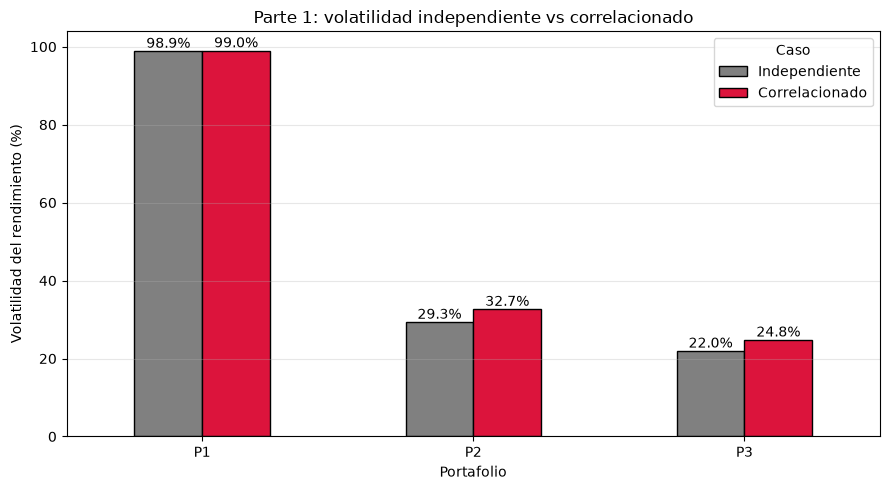

In [17]:
comparar_volatilidad(tabla_p1, "Parte 1: volatilidad independiente vs correlacionado")

### ¿Qué observamos?

La gráfica de barras resume el efecto: la correlación **no toca a P1** y **aumenta la volatilidad de P2 y P3** unos 3 puntos porcentuales. La diversificación sigue funcionando, porque P2 y P3 siguen siendo mucho menos riesgosos que P1, pero funciona menos de lo que el modelo independiente prometía.

---

# Parte 2. Ejercicio B con $V_0 = 100{,}000$ MXN

**Activos:** AAPL, MSFT y NVDA, los tres en USD, más el tipo de cambio.

**Portafolios:**

| Portafolio | Pesos $w$ (AAPL, MSFT, NVDA) |
|---|---|
| P1 | [1, 0, 0] |
| P2 | [0.33, 0.33, 0.34] |
| P3 | [0.2, 0.2, 0.6] |

Se usa la misma simulación de clase, con $\mu = 0$ para centrar los escenarios en el precio actual:

$$Z = 0 + L\,\varepsilon \qquad S_T = S_0\, e^{Z}$$

Como la inversión es en pesos y las acciones cotizan en dólares, el tipo de cambio también se simula y entra en la correlación.

### Descarga de AAPL, MSFT, NVDA y tipo de cambio (últimos 3 años)

In [18]:
tickers_tec = ["AAPL", "MSFT", "NVDA"]
todos_tec   = tickers_tec + [fx]

data_tec = yf.download(todos_tec, start="2023-11-01", end="2026-11-01",
                       auto_adjust=True, progress=False)

precios_tec = data_tec["Close"][todos_tec].dropna()
print(f"Observaciones: {len(precios_tec)}")
precios_tec.tail()

Observaciones: 751


Ticker,AAPL,MSFT,NVDA,MXN=X
Date,,,,
2026-10-26,343.910004,532.599976,216.000000,18.71900
2026-10-27,347.100006,531.330017,217.940002,18.55020
2026-10-28,343.829987,531.010010,215.380005,18.68704
2026-10-29,348.910004,530.140015,213.660004,18.63179
2026-10-30,344.630005,521.909973,204.639999,18.85210


### Volatilidades y matriz de covarianzas anualizada

In [19]:
log_ret_tec = np.log(precios_tec / precios_tec.shift(1)).dropna()

sigma_tec = log_ret_tec.std() * np.sqrt(252)
Sigma_tec = log_ret_tec.cov() * 252
S0_tec    = precios_tec.iloc[-1]

pd.DataFrame({"S0": S0_tec, "sigma": sigma_tec}).round(4)

,S0,sigma
Ticker,,
AAPL,344.6300,0.2662
MSFT,521.9100,0.2587
NVDA,204.6400,0.4652
MXN=X,18.8521,0.1121


### Correlación histórica entre los factores

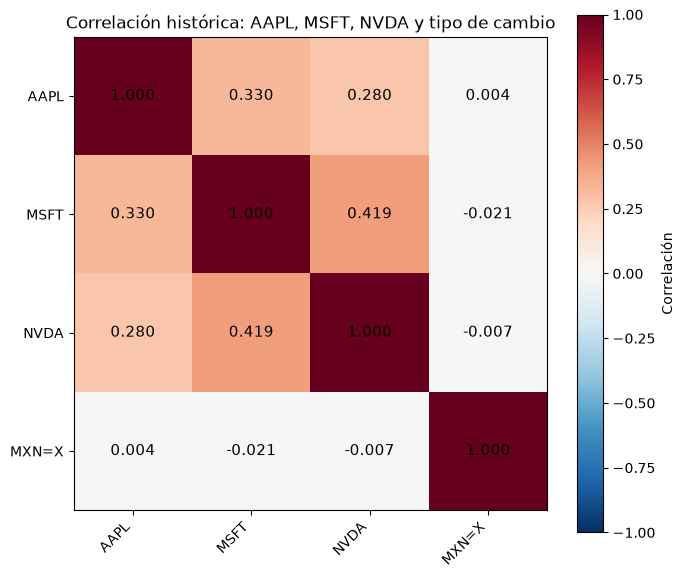

In [20]:
correlacion_tec = log_ret_tec.corr()
graficar_correlacion(correlacion_tec, "Correlación histórica: AAPL, MSFT, NVDA y tipo de cambio")

### ¿Qué observamos?

Aquí las correlaciones entre acciones son **claramente más altas** que en la Parte 1: entre 0.28 y 0.42, contra 0.02 a 0.22. Las tres son tecnológicas estadounidenses y reaccionan a lo mismo: tasas de interés, expectativas de inteligencia artificial y el ánimo general del Nasdaq. La más alta es MSFT con NVDA, dos de las empresas más expuestas a la inversión en inteligencia artificial.

Suponer independencia aquí es mucho menos razonable que en la Parte 1.

### Matrices $L$ de los dos casos

In [21]:
L_ind_tec  = np.diag(sigma_tec.values)
L_corr_tec = np.linalg.cholesky(Sigma_tec.values)

print(f"¿L · Lᵀ reconstruye Σ? {np.allclose(L_corr_tec @ L_corr_tec.T, Sigma_tec.values)}")
print("\nMatriz L con correlación:")
print(pd.DataFrame(L_corr_tec, index=todos_tec, columns=todos_tec).round(4))

¿L · Lᵀ reconstruye Σ? True

Matriz L con correlación:
         AAPL    MSFT    NVDA   MXN=X
AAPL   0.2662  0.0000  0.0000  0.0000
MSFT   0.0854  0.2442  0.0000  0.0000
NVDA   0.1304  0.1611  0.4165  0.0000
MXN=X  0.0005 -0.0026  0.0000  0.1121


### Choques independientes y correlacionados con los mismos $\varepsilon$

In [22]:
np.random.seed(42)
epsilon_tec = np.random.normal(0, 1, [M, len(todos_tec)])

Z_ind_tec  = 0 + epsilon_tec @ L_ind_tec.T
Z_corr_tec = 0 + epsilon_tec @ L_corr_tec.T

print("Correlación simulada, caso independiente:")
print(pd.DataFrame(Z_ind_tec, columns=todos_tec).corr().round(3))
print("\nCorrelación simulada, caso correlacionado:")
print(pd.DataFrame(Z_corr_tec, columns=todos_tec).corr().round(3))

Correlación simulada, caso independiente:
        AAPL   MSFT   NVDA  MXN=X
AAPL   1.000 -0.002 -0.001 -0.015
MSFT  -0.002  1.000  0.002  0.015
NVDA  -0.001  0.002  1.000  0.008
MXN=X -0.015  0.015  0.008  1.000

Correlación simulada, caso correlacionado:
        AAPL   MSFT   NVDA  MXN=X
AAPL   1.000  0.335  0.279 -0.011
MSFT   0.335  1.000  0.416 -0.011
NVDA   0.279  0.416  1.000  0.001
MXN=X -0.011 -0.011  0.001  1.000


### ¿Qué observamos?

Igual que en la Parte 1: el caso independiente tiene correlaciones de cero y el correlacionado recupera las históricas. Como AAPL va primero en $L$, **AAPL es idéntico en los dos casos**.

### Precios a un año y precios en pesos

$$S^{MXN}_{T,i} = S_{T,i} \cdot X_T$$

In [23]:
ST_ind_tec  = pd.DataFrame(S0_tec.values * np.exp(Z_ind_tec),  columns=todos_tec)
ST_corr_tec = pd.DataFrame(S0_tec.values * np.exp(Z_corr_tec), columns=todos_tec)

X0_tec = S0_tec[fx]
S0_mxn_tec = S0_tec[tickers_tec].values * X0_tec

ST_mxn_ind_tec  = ST_ind_tec[tickers_tec].values  * ST_ind_tec[fx].values[:, None]
ST_mxn_corr_tec = ST_corr_tec[tickers_tec].values * ST_corr_tec[fx].values[:, None]

pd.Series(S0_mxn_tec, index=tickers_tec, name="S0 en MXN").round(2)

AAPL    6497.00
MSFT    9839.10
NVDA    3857.89
Name: S0 en MXN, dtype: float64

### Acciones enteras y pesos reales de cada portafolio

Una acción de MSFT cuesta casi 10,000 pesos, así que con acciones enteras los pesos reales se alejan de los planeados. En P2 sobra cerca del 7% en efectivo.

In [24]:
portafolios_tec = {
    "P1": np.array([1, 0, 0]),
    "P2": np.array([0.33, 0.33, 0.34]),
    "P3": np.array([0.2, 0.2, 0.6]),
}

acciones_tec = {}
efectivo_tec = {}
for nombre, w in portafolios_tec.items():
    N = np.floor(w * V0 / S0_mxn_tec)
    acciones_tec[nombre] = N
    efectivo_tec[nombre] = V0 - np.sum(N * S0_mxn_tec)

tabla_acc_tec = pd.DataFrame(acciones_tec, index=tickers_tec).T.astype(int)
for i, tk in enumerate(tickers_tec):
    tabla_acc_tec[f"Peso real {tk} (%)"] = [acciones_tec[p][i] * S0_mxn_tec[i] / V0 * 100
                                            for p in portafolios_tec]
tabla_acc_tec["Efectivo"] = pd.Series(efectivo_tec)
tabla_acc_tec.round(2)

,AAPL,MSFT,NVDA,Peso real AAPL (%),Peso real MSFT (%),Peso real NVDA (%),Efectivo
P1,15,0,0,97.45,0.00,0.00,2545.01
P2,5,3,8,32.48,29.52,30.86,7134.55
P3,3,2,15,19.49,19.68,57.87,2962.40


### Valor final y tabla comparativa

In [25]:
VT_ind_tec  = pd.DataFrame({p: ST_mxn_ind_tec  @ N + efectivo_tec[p] for p, N in acciones_tec.items()})
VT_corr_tec = pd.DataFrame({p: ST_mxn_corr_tec @ N + efectivo_tec[p] for p, N in acciones_tec.items()})

tabla_p2 = resumen_casos(VT_ind_tec, VT_corr_tec, V0)
tabla_p2.round(2)

E[V_T]  Rend. esperado (%)  Volatilidad (%)  \
Portafolio Caso                                                             
P1         Independiente   104330.34                4.33            29.92   
           Correlacionado  104344.96                4.34            29.96   
P2         Independiente   106279.71                6.28            23.99   
           Correlacionado  106232.99                6.23            28.45   
P3         Independiente   108586.71                8.59            35.42   
           Correlacionado  108490.34                8.49            38.50   

                           P(pérdida) (%)  Percentil 5%  Percentil 95%  
Portafolio Caso                                                         
P1         Independiente            49.71      63362.46      159417.98  
           Correlacionado           49.69      63389.49      159524.49  
P2         Independiente            44.59      73475.37      150600.70  
           Correlacionado           46.85      68214.92      159057.00  
P3         Independiente            48.07      65134.04      175801.58  
           Correlacionado           48.67      60697.01      181133.41

### ¿Qué observamos?

- **Con $\mu = 0$, los valores esperados quedan cerca de $V_0$** y la probabilidad de pérdida ronda 45 a 50% en todos los casos. Las medias son un poco mayores a 100,000 solo por la convexidad de la exponencial.
- **El valor esperado vuelve a ser casi igual** en los dos casos.
- **P1 queda prácticamente igual**, porque solo tiene AAPL y la única diferencia es su correlación con el tipo de cambio, que es muy baja.
- **P2 es el más afectado:** su volatilidad sube de cerca de 24% a cerca de 28.6%, casi 19% más en términos relativos, y el percentil 5% empeora unos 5,000 pesos. Es el portafolio más repartido, así que es el que más dependía de que los activos se compensaran entre sí.
- **P3 sube menos en términos relativos** (de cerca de 35.4% a 38.7%), porque su riesgo está dominado por el 60% en NVDA, que no depende de la correlación.

### Distribución del valor final: independiente vs correlacionado

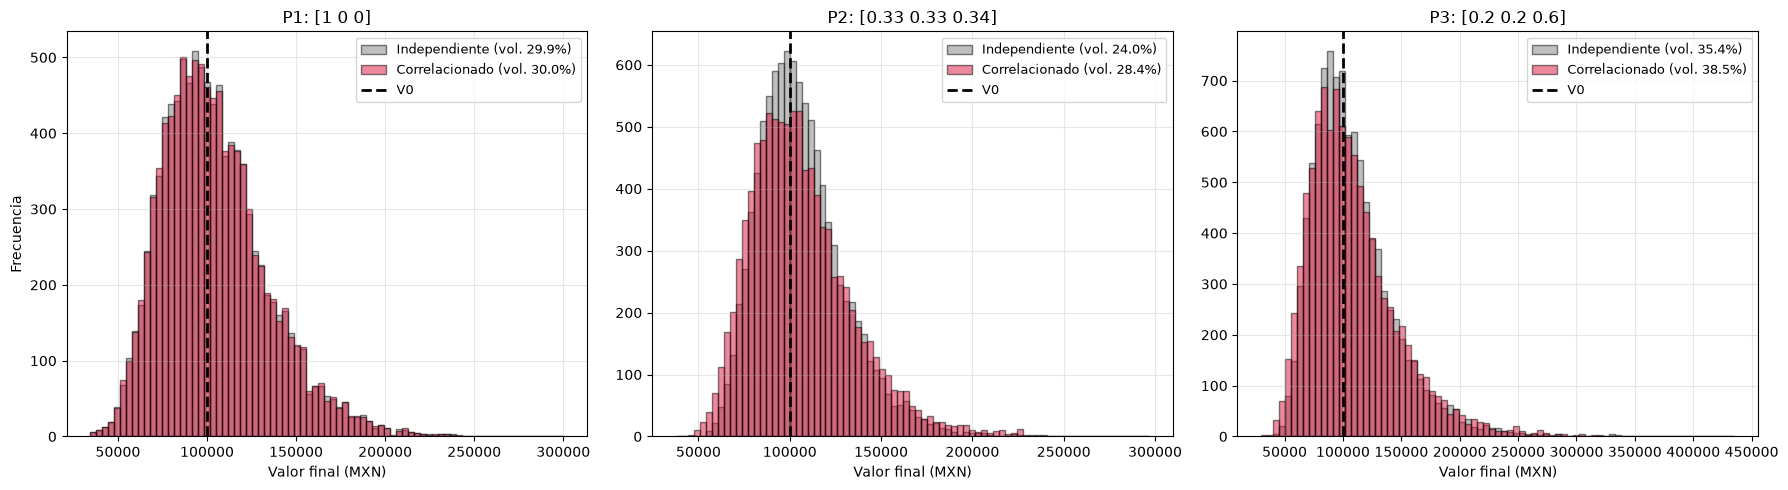

In [26]:
comparar_histogramas(VT_ind_tec, VT_corr_tec, V0, portafolios_tec)

### ¿Qué observamos?

La separación entre los dos histogramas de P2 y P3 es más visible que en la Parte 1. En el caso correlacionado aparecen más escenarios en los que las tres acciones caen al mismo tiempo, y la cola izquierda (pérdidas) se alarga. También crece la cola derecha, porque los escenarios en los que suben juntas también son más frecuentes.

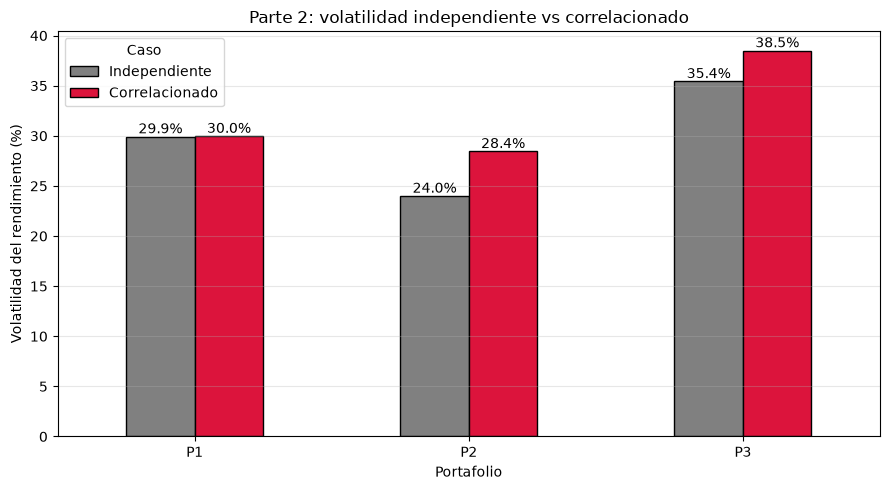

In [27]:
comparar_volatilidad(tabla_p2, "Parte 2: volatilidad independiente vs correlacionado")

### ¿Qué observamos?

Con activos del mismo sector, ignorar la correlación hace que **P2 parezca bastante más seguro de lo que es**. En el modelo independiente P2 tiene una volatilidad claramente menor que P1, mientras que con correlación la diferencia entre ambos se reduce bastante.

---

# Comparación de las dos partes

Cuánto aumenta la volatilidad de cada portafolio al pasar del modelo independiente al correlacionado.

In [28]:
cambio = pd.DataFrame({
    "Parte 1 (sectores distintos)": tabla_p1["Volatilidad (%)"].unstack()["Correlacionado"]
                                    - tabla_p1["Volatilidad (%)"].unstack()["Independiente"],
    "Parte 2 (mismo sector)":       tabla_p2["Volatilidad (%)"].unstack()["Correlacionado"]
                                    - tabla_p2["Volatilidad (%)"].unstack()["Independiente"],
})
print("Cambio en la volatilidad al incluir la correlación (puntos porcentuales):")
cambio.round(2)

Cambio en la volatilidad al incluir la correlación (puntos porcentuales):


,Parte 1 (sectores distintos),Parte 2 (mismo sector)
Portafolio,,
P1,0.12,0.04
P2,3.31,4.45
P3,2.83,3.07


---

# Conclusiones

**1. La correlación no cambia el valor esperado, solo el riesgo.**
En las dos partes, $E[V_T]$ es prácticamente igual con y sin correlación. El valor esperado de un portafolio es una suma ponderada de valores esperados individuales, y la correlación solo afecta cómo se mueven los activos entre sí. Lo que sí cambia es la dispersión: la volatilidad, la probabilidad de pérdida y los percentiles extremos.

**2. Un portafolio de un solo activo no depende de la correlación.**
P1 da prácticamente el mismo resultado en los dos casos de cada parte; la única diferencia viene de la correlación del activo con el tipo de cambio, que es casi cero. La correlación solo importa cuando hay algo que combinar.

**3. Incluso entre sectores distintos, la independencia es un supuesto optimista.**
En la Parte 1 las correlaciones son bajas (como mucho 0.22), y aun así la volatilidad de P2 y P3 sube alrededor de 3 puntos porcentuales y la probabilidad de pérdida aumenta. Como todas las correlaciones relevantes son positivas, suponer que son cero hace que el portafolio parezca más diversificado de lo que es.

**4. Dentro del mismo sector, la independencia subestima el riesgo de forma importante.**
En la Parte 2 las correlaciones son de 0.28 a 0.42, y la volatilidad del portafolio repartido (P2) aumenta casi 19% relativo. Las tres tecnológicas reaccionan a los mismos factores, así que tienden a caer juntas justo cuando más se necesitaría que se compensaran.

**5. Entre más repartido el portafolio, más le afecta la correlación.**
El portafolio con pesos iguales (P2) es el más afectado en las dos partes. P3 en la Parte 2 se afecta menos porque su riesgo está concentrado en NVDA, y el riesgo de un solo activo no depende de la correlación.

**6. Implicación práctica.**
Diversificar sí reduce el riesgo en todos los casos, pero el beneficio depende de qué tan poco correlacionados estén los activos. Para medir el riesgo de un portafolio con Monte Carlo hay que simular los activos con su correlación; de lo contrario, medidas como el percentil 5% (la base del VaR) salen menos severas de lo que realmente son. Para diversificar de verdad conviene combinar sectores, países o clases de activo distintos, no varias acciones de la misma industria.